# **Exploring Factors Linked to Heart Disease**

### **Group Members:**
1. Ramith Wijesinghe
2. Brian Liu
3. Zhuoxin Xia

## **Introduction**

Heart disease is a broad term for problems that affect how the heart works. These conditions can make it harder for the heart to pump blood around the body.
Factors linked to heart disease such as high blood pressure, smoking, and diabetes are important because they can raise a person’s risk and help guide prevention and treatment.

## **Topic**
This project examines how gender, existing health conditions, exercise habits, and other lifestyle factors are associated with heart disease.

In [35]:
#code imports
import pandas as pd
import numpy as np
import requests
import seaborn as sns
import sqlite3
import matplotlib.pyplot as plt

In [36]:
#pull csv file
df = pd.read_csv("health.csv")
#we will create a copy for before and after analysis
df_raw = df.copy()
df.head()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,NaN,No,...,NaN,NaN,NaN,No,No,Yes,No,"Yes, received tetanus shot but not sure what type",No,No
1,Alabama,Female,Excellent,0.0,0.0,NaN,No,6.0,NaN,No,...,1.60,68.04,26.57,No,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
2,Alabama,Female,Very good,2.0,3.0,Within past year (anytime less than 12 months ...,Yes,5.0,NaN,No,...,1.57,63.50,25.61,No,No,No,No,NaN,No,Yes
3,Alabama,Female,Excellent,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,7.0,NaN,No,...,1.65,63.50,23.30,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,No
4,Alabama,Female,Fair,2.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,NaN,No,...,1.57,53.98,21.77,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,No


In [37]:
print(df.shape)


(445132, 40)


# **Analyse data values and clean**

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 445132 entries, 0 to 445131
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      445132 non-null  str    
 1   Sex                        445132 non-null  str    
 2   GeneralHealth              443934 non-null  str    
 3   PhysicalHealthDays         434205 non-null  float64
 4   MentalHealthDays           436065 non-null  float64
 5   LastCheckupTime            436824 non-null  str    
 6   PhysicalActivities         444039 non-null  str    
 7   SleepHours                 439679 non-null  float64
 8   RemovedTeeth               433772 non-null  str    
 9   HadHeartAttack             442067 non-null  str    
 10  HadAngina                  440727 non-null  str    
 11  HadStroke                  443575 non-null  str    
 12  HadAsthma                  443359 non-null  str    
 13  HadSkinCancer              441989 non-nu

In [39]:
#get nul vals
null_vals = df.isnull().sum()
print(null_vals)
#get how many null values as a percentage
null_vals_pct = ( null_vals / len(df) * 100).round(2)
print(null_vals_pct[null_vals_pct > 0].sort_values(ascending=False))

State                            0
Sex                              0
GeneralHealth                 1198
PhysicalHealthDays           10927
MentalHealthDays              9067
LastCheckupTime               8308
PhysicalActivities            1093
SleepHours                    5453
RemovedTeeth                 11360
HadHeartAttack                3065
HadAngina                     4405
HadStroke                     1557
HadAsthma                     1773
HadSkinCancer                 3143
HadCOPD                       2219
HadDepressiveDisorder         2812
HadKidneyDisease              1926
HadArthritis                  2633
HadDiabetes                   1087
DeafOrHardOfHearing          20647
BlindOrVisionDifficulty      21564
DifficultyConcentrating      24240
DifficultyWalking            24012
DifficultyDressingBathing    23915
DifficultyErrands            25656
SmokerStatus                 35462
ECigaretteUsage              35660
ChestScan                    56046
RaceEthnicityCategor

In [40]:
#check for how many duplicate rows.
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 157


In [41]:
#go through each columns unique values and the sum 
for c in df.select_dtypes(include="str").columns:
    if df[c].nunique() <= 12 and c != "State":
        print("\n"+ c)
        print(df[c].value_counts(dropna=False))


Sex
Sex
Female    235893
Male      209239
Name: count, dtype: int64

GeneralHealth
GeneralHealth
Very good    148444
Good         143598
Excellent     71878
Fair          60273
Poor          19741
NaN            1198
Name: count, dtype: int64

LastCheckupTime
LastCheckupTime
Within past year (anytime less than 12 months ago)         350944
Within past 2 years (1 year but less than 2 years ago)      41919
Within past 5 years (2 years but less than 5 years ago)     24882
5 or more years ago                                         19079
NaN                                                          8308
Name: count, dtype: int64

PhysicalActivities
PhysicalActivities
Yes    337559
No     106480
NaN      1093
Name: count, dtype: int64

RemovedTeeth
RemovedTeeth
None of them              233455
1 to 5                    129294
6 or more, but not all     45570
All                        25453
NaN                        11360
Name: count, dtype: int64

HadHeartAttack
HadHeartAttack
No     4169

In [42]:
before_row = len(df)
print(before_row)
# now we will remove the duplicate rows and reset index
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before_row - len(df)} duplicate rows.")

445132
Removed 157 duplicate rows.


From the analysis above, we will drop three columns which has a lot of missing values, and will not be of use for our future analysis. 

- `TetanusLast10Tdap`: 18.54%
- `PneumoVaxEver`: 17.31%
- `HIVTesting`: 14.86%

In [43]:
#now we drop columns that we might not need for this 
df= df.drop(columns = ["TetanusLast10Tdap", "PneumoVaxEver", "HIVTesting"])

We go through all the columns with yes and no values and convert them to 1 and 0. 

In [44]:
#convert yes and no to 0 and 1s
yes_no_cols = [ c for c in df.columns 
                if set(df[c].dropna().unique()) == {"Yes", "No"}
              ] 
print(yes_no_cols)

for x in yes_no_cols:
    df[x] = df[x].map({"Yes":1, "No":0})


['PhysicalActivities', 'HadHeartAttack', 'HadAngina', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'ChestScan', 'AlcoholDrinkers', 'FluVaxLast12', 'HighRiskLastYear']


Now we will look at the inconsistant categories. We will try to make sense of the values.

In [45]:
#to make things simpler we will categorise some days and everydays as one.

df["ECigarette"] = df["ECigaretteUsage"].map({      
    "Never used e-cigarettes in my entire life": "Never",
    "Not at all (right now)": "Former",                
    "Use them some days": "Current",
    "Use them every day": "Current"})

df["Smoking"] = df["SmokerStatus"].map({               
    "Never smoked": "Never",
    "Former smoker": "Former",
    "Current smoker - now smokes every day": "Current",
    "Current smoker - now smokes some days": "Current"})

#look into other inconsistancies that we can summarise
df["CovidPos"] = df["CovidPos"].map({                 
    "No": 0,
    "Yes": 1,
    "Tested positive using home test without a health professional": 1})

df["HadDiabetes"] = df["HadDiabetes"].map({            
    "Yes": "Yes",
    "No": "No",
    "No, pre-diabetes or borderline diabetes": "Pre-diabetes",
    "Yes, but only during pregnancy (female)": "Diabetic at Pregnancy"})

df["LastCheckup"] = df["LastCheckupTime"].map({        
    "Within past year (anytime less than 12 months ago)": "<1 year",
    "Within past 2 years (1 year but less than 2 years ago)": "1-2 years",
    "Within past 5 years (2 years but less than 5 years ago)": "2-5 years",
    "5 or more years ago": "5+ years"})



In [46]:
# since we created three new labels to simplify, we remove the old ones
df = df.drop(columns=["SmokerStatus", "ECigaretteUsage", "LastCheckupTime"])  

In [47]:
#checking changes
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- State ---
State
Washington              26142
New York                17784
Minnesota               16816
Ohio                    16482
Maryland                16410
Texas                   14237
Florida                 13385
Wisconsin               11273
Kansas                  11243
Massachusetts           11027
California              10948
Maine                   10646
Indiana                 10459
Virginia                10414
Arizona                 10184
Michigan                10054
South Carolina          10034
Utah                     9823
Connecticut              9771
Colorado                 9361
Georgia                  9234
Iowa                     8948
Vermont                  8801
New Jersey               8196
Hawaii                   7747
Nebraska                 7472
Missouri                 7438
South Dakota             7423
Montana                  7047
New Hampshire            6754
Idaho                    6280
Rhode Island             5891
Alaska             

**We look into impossible values that does not make sense and leave them as missing so they will be handled as black values.**

Adults shorter than 1.2 m or taller than 2.3 m are almost errors.

Weights outside 30–300 kg are not credible

Sleep hours less than 2 or greater than 16 does not make sense.

In [48]:
limits = {"HeightInMeters": (1.2, 2.3),                
          "WeightInKilograms": (30, 300),
          "SleepHours": (2, 16)}

In [49]:
for col, (low, high) in limits.items():               
    bad = (df[col] < low) | (df[col] > high)           
    print(col, "impossible values:", bad.sum())        
    df.loc[bad, col] = np.nan 

HeightInMeters impossible values: 143
WeightInKilograms impossible values: 72
SleepHours impossible values: 1601


**Calculate unknown BMI values and fix any related**

In [50]:
#BMI calculation equation
bmi_eq = (df["WeightInKilograms"] / df["HeightInMeters"] ** 2).round(2)
#null BMIs that can be calculated
print("BMI recoverable:", (df["BMI"].isnull() & bmi_eq.notnull()).sum())

#check for BMIs that does not match equation answer
print("BMI mismatch:", ((df["BMI"] - bmi_eq).abs() > 0.5).sum())

#fill the BMI from empty areas
df["BMI"] = df["BMI"].fillna(bmi_eq)

BMI recoverable: 2177
BMI mismatch: 7


**Now we create the target variable that takes both HadHeartAttack and HadAngina and summarise it as having a HeartDisease**

In [51]:
df["HeartDisease"] = np.nan
df.loc[(df["HadHeartAttack"] == 0) & (df["HadAngina"] == 0), "HeartDisease"] = 0
df.loc[(df["HadHeartAttack"] == 1) | (df["HadAngina"] == 1), "HeartDisease"] = 1
print(df["HeartDisease"].value_counts(dropna=False))

HeartDisease
0.0    400208
1.0     39751
NaN      5016
Name: count, dtype: int64


**Now we remove columns with blank HeartDisease since this is the ooutcome we are going to study. guessing all the Nan outcomes would give falls results**

In [52]:
before = len(df)
df = df.dropna(subset=["HeartDisease"]).reset_index(drop=True) 
df["HeartDisease"] = df["HeartDisease"].astype(int) 
print("Dropped: ", before - len(df))
df = df.drop(columns=["HadHeartAttack", "HadAngina"])

Dropped:  5016


# **Filling Missing values with median and other variables**

In [53]:
#change age category into a sensible format
lo = df["AgeCategory"].str.extract(r"Age (\d+)")[0].astype(float)   
hi = df["AgeCategory"].str.extract(r"to (\d+)")[0].astype(float)    
df["AgeMid"] = ((lo + hi) / 2).fillna(lo + 2)                       
df[["AgeCategory", "AgeMid"]].drop_duplicates().sort_values("AgeMid")
df["AgeCategory"] = df["AgeCategory"].fillna("Unknown")

df["AgeMid"] = df["AgeMid"].fillna(df["AgeMid"].median())

In [54]:
#GeneralHealth
# now we look into other columns that might have blanks and fill them up
num_cols = ["PhysicalHealthDays", "MentalHealthDays", "SleepHours",
            "HeightInMeters", "WeightInKilograms", "BMI"]

for c in num_cols:                                                       
    group_median = df.groupby(["Sex", "AgeMid"])[c].transform("median")  
    df[c] = df[c].fillna(group_median)                                   
    df[c] = df[c].fillna(df[c].median())                                 

text_cols = ["PhysicalActivities", "HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
               "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis", "DeafOrHardOfHearing",
               "BlindOrVisionDifficulty", "DifficultyConcentrating", "DifficultyWalking",
               "DifficultyDressingBathing", "DifficultyErrands", "ChestScan", "AlcoholDrinkers",
               "FluVaxLast12", "HighRiskLastYear", "CovidPos"]
for c in text_cols:
    most_common = df[c].mode()[0]            
    df[c] = df[c].fillna(most_common)        
    df[c] = df[c].astype(int)

missing_cols = ["GeneralHealth", "RemovedTeeth", "HadDiabetes", "Smoking",
            "ECigarette", "LastCheckup", "RaceEthnicityCategory", "AgeCategory"]
for c in missing_cols:
    df[c] = df[c].fillna("Unknown")

print("Missing: ", df.isnull().sum().sum())

Missing:  0


**Now generate clean data set**


In [55]:
#remove any duplicates created in the process
df = df.drop_duplicates().reset_index(drop=True) 
df.to_csv("health_clean.csv", index=False) 

In [56]:
print("Raw shape  :", df_raw.shape)                 
print("Clean shape:", df.shape)                     
print("Missing values:", df.isnull().sum().sum())  
print("Duplicates    :", df.duplicated().sum())   


Raw shape  : (445132, 40)
Clean shape: (439890, 37)
Missing values: 0
Duplicates    : 0


## Exploratory Data Analysis (EDA)

### Smoking Status vs. Heart Disease

In [57]:
# Compare smoking groups
order = ["Never", "Former", "Current"]

smoking_data = df[df["Smoking"].isin(order)]

rates = (
    smoking_data.groupby("Smoking")["HeartDisease"]
    .mean()
    .reindex(order) * 100
)

print(rates.round(2))

Smoking
Never       6.56
Former     13.58
Current    11.55
Name: HeartDisease, dtype: float64


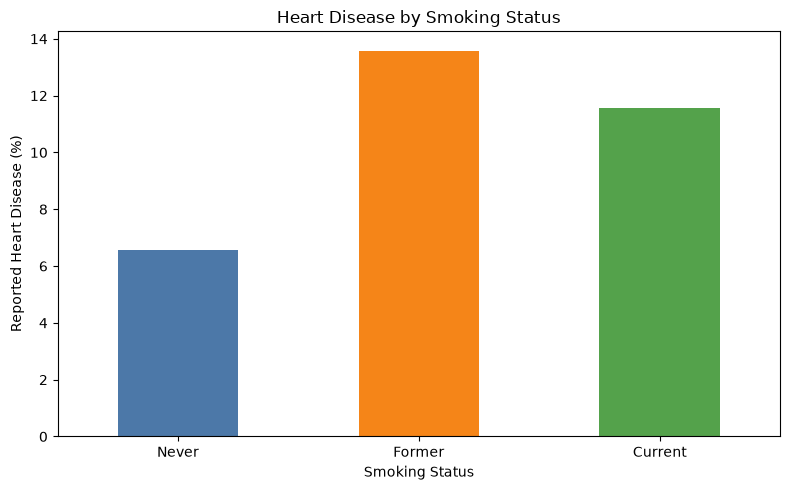

In [58]:
# Visualize the group percentages
plt.figure(figsize=(8, 5))

rates.plot(kind="bar", color=["#4C78A8", "#F58518", "#54A24B"])

plt.title("Heart Disease by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Reported Heart Disease (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [59]:
from scipy.stats import chi2_contingency

# Create a contingency table
table = pd.crosstab(
    smoking_data["Smoking"],
    smoking_data["HeartDisease"]
)

# Run Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

print(table)
print("Chi-square:", chi2)
print("p-value:", p_value)

HeartDisease       0      1
Smoking                    
Current        43535   5686
Former         97111  15265
Never         227717  15993
Chi-square: 4978.885839276863
p-value: 0.0


Based on our results, people who never smoked had the lowest heart disease rate (6.56%), while former smokers had the highest (13.58%). The chi-square test also showed a significant relationship (p < 0.001). This suggests that smoking status is associated with heart disease, but other factors like age and health conditions may also affect the results.

### BMI vs. Heart Disease

In [60]:
# Compare BMI between two groups
bmi_data = df[["HeartDisease", "BMI"]].dropna()

print(
    bmi_data.groupby("HeartDisease")["BMI"]
    .agg(["count", "mean", "median"])
    .round(2)
)

               count   mean  median
HeartDisease                       
0             400139  28.32   27.46
1              39751  29.28   28.06


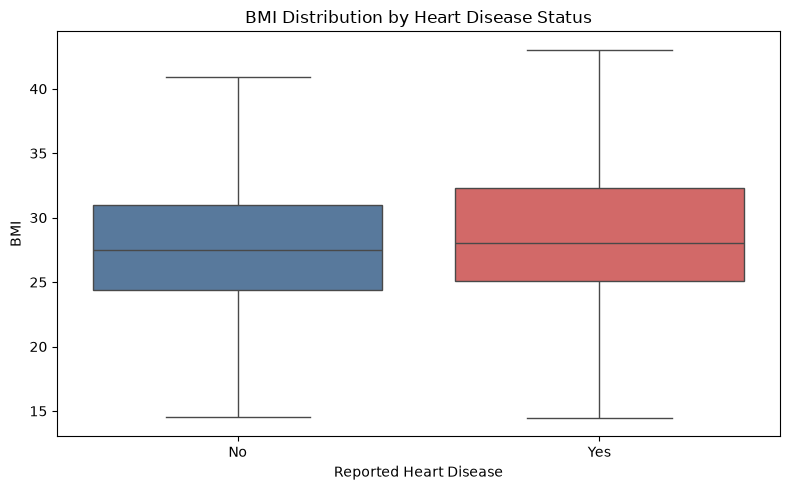

In [61]:
# Visualize BMI distribution
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=bmi_data,
    x="HeartDisease",
    y="BMI",
    order=[0, 1],
    showfliers=False,
    hue="HeartDisease",
    palette={0: "#4C78A8", 1: "#E45756"},
    legend=False
)

plt.title("BMI Distribution by Heart Disease Status")
plt.xlabel("Reported Heart Disease")
plt.ylabel("BMI")
plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()

In [62]:
from scipy.stats import mannwhitneyu

# Separate BMI values by heart disease status
bmi_no = bmi_data[bmi_data["HeartDisease"] == 0]["BMI"]
bmi_yes = bmi_data[bmi_data["HeartDisease"] == 1]["BMI"]

# Run Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    bmi_no, bmi_yes, alternative="two-sided"
)

print("U statistic:", u_stat)
print("p-value:", p_value)

U statistic: 7189966451.5
p-value: 3.834669746072446e-219


Our results show that people who reported heart disease had a slightly higher average BMI (29.28 vs. 28.32). The Mann–Whitney U test also showed a significant difference (p < 0.001). However, the difference is relatively small, so BMI alone may not explain heart disease.

### Age vs. Heart Disease

In [63]:
# Calculate heart disease rates by age group
age_data = df[df["AgeCategory"] != "Unknown"]

age_summary = (
    age_data.groupby(["AgeCategory", "AgeMid"], as_index=False)
    .agg(
        count=("HeartDisease", "size"),
        rate=("HeartDisease", "mean")
    )
    .sort_values("AgeMid")
)

age_summary["rate_pct"] = age_summary["rate"] * 100

print(age_summary[["AgeCategory", "count", "rate_pct"]].round(2))

        AgeCategory  count  rate_pct
0      Age 18 to 24  26742      0.75
1      Age 25 to 29  21867      0.97
2      Age 30 to 34  25649      1.22
3      Age 35 to 39  28327      1.66
4      Age 40 to 44  29720      2.37
5      Age 45 to 49  28305      3.77
6      Age 50 to 54  33348      5.46
7      Age 55 to 59  36462      7.92
8      Age 60 to 64  44006     10.01
9      Age 65 to 69  46548     12.58
10     Age 70 to 74  42929     15.86
11     Age 75 to 79  31973     19.42
12  Age 80 or older  35285     23.29


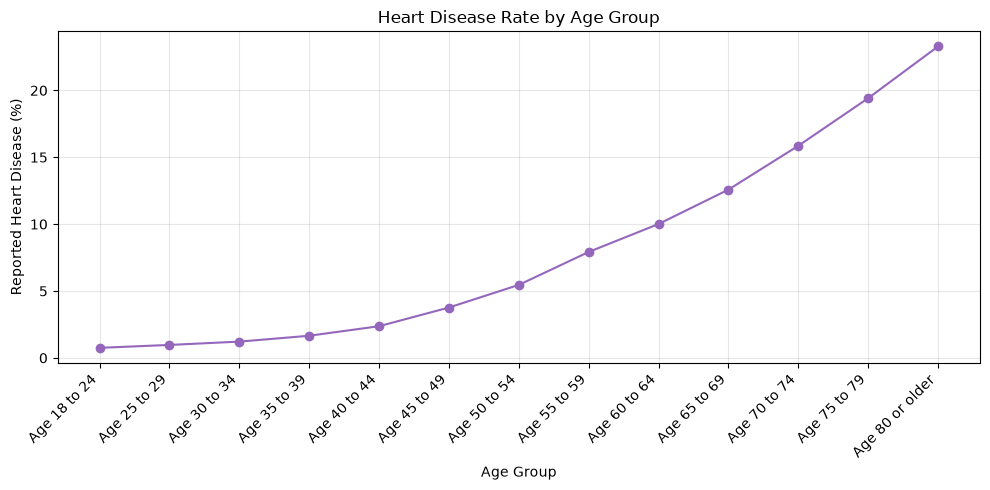

In [64]:
# Visualize heart disease rates across age groups
plt.figure(figsize=(10, 5))

plt.plot(
    age_summary["AgeCategory"],
    age_summary["rate_pct"],
    marker="o",
    color="#9467BD"
)

plt.title("Heart Disease Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Reported Heart Disease (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [65]:
from scipy.stats import spearmanr

# Prepare data for correlation test
age_test = age_data[["AgeMid", "HeartDisease"]].dropna()

# Run Spearman correlation
rho, p_value = spearmanr(
    age_test["AgeMid"],
    age_test["HeartDisease"]
)

print("Spearman correlation:", rho)
print("p-value:", p_value)

Spearman correlation: 0.2436612176664864
p-value: 0.0


Our results show that the reported heart disease rate increases with age, from 0.75% for ages 18–24 to 23.29% for people aged 80 and older. The Spearman test also showed a significant positive correlation (ρ = 0.244, p < 0.001). This suggests that age is associated with heart disease, although other health factors may also play a role.